# PoC Emergencias 123 Bogotá: PySpark frente a Pandas

Actividad 2, tareas 2.2 (PoC en PySpark) y 2.4 (métricas de rendimiento), en versión sencilla.

El pipeline lee los 3 CSV desde Drive, limpia los datos, valida su calidad y guarda un Parquet particionado por año,
mes y localidad. Reglas de limpieza:

1. Solo se eliminan las filas **idénticas**. Un mismo incidente puede tener varios pacientes o despachos.
2. El texto `N/A` es un dato faltante: en género se reemplaza por `NO REGISTRA`.
3. La edad se pasa a años según su unidad (años, meses, días u horas).
4. La diferencia entre el despacho y `RECEPCION` se reporta como minutos hasta `RECEPCION`, no como tiempo de respuesta.

Después se ejecuta 3 veces, se compara con Pandas y se mide con 1 y 2 años de datos.

## 1. Entorno

In [ ]:
!pip install -q pyspark

import os, gc, time, shutil, threading
from datetime import datetime
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType
from pyspark.sql.functions import col, trim, upper, to_timestamp, year, month, coalesce, lit, when, input_file_name

spark = SparkSession.builder \
    .appName("PoC_Emergencias123_Bogota") \
    .config("spark.driver.memory", "4g") \
    .config("spark.driver.maxResultSize", "2g") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.sql.adaptive.skewJoin.enabled", "true") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.adaptive.advisoryPartitionSizeInBytes", "64MB") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()

PATH_DRIVE = "/content/drive/MyDrive/BigData_U2/datos/"
if not os.path.exists(PATH_DRIVE):
    from google.colab import drive
    drive.mount('/content/drive')

archivos_csv = [PATH_DRIVE + "llamadas123_julio_2026.csv",
                PATH_DRIVE + "llamadaslinea123agosto2026.csv",
                PATH_DRIVE + "llamadaslinea123Septiembre.csv"]
SALIDA = "/content/drive/MyDrive/BigData_U2/resultados/poc_sencillo/"
os.makedirs(SALIDA + "logs", exist_ok=True)
TEMPORAL = "/content/tmp_poc"
print(f"✓ Spark {spark.version} listo · resultados en {SALIDA}")

✓ Spark 4.0.5 listo · resultados en /content/drive/MyDrive/BigData_U2/resultados/poc_sencillo/


## 2. Pipeline en PySpark

Lectura con esquema explícito, limpieza, validación y Parquet particionado por año, mes y localidad. El tiempo se mide
de la lectura a la exportación, y el log se escribe con los valores calculados en cada ejecución.

In [ ]:
esquema = StructType([
    StructField("NUMERO_INCIDENTE", StringType(), True),
    StructField("FECHA_INICIO_DESPLAZAMIENTO_MOVIL", StringType(), True),
    StructField("CODIGO_LOCALIDAD", IntegerType(), True),
    StructField("LOCALIDAD", StringType(), True),
    StructField("EDAD", DoubleType(), True),
    StructField("UNIDAD", StringType(), True),
    StructField("GENERO", StringType(), True),
    StructField("TIPO_INCIDENTE", StringType(), True),
    StructField("PRIORIDAD_FINAL", StringType(), True),
    StructField("RECEPCION", StringType(), True)
])


def pipeline_spark(rutas, destino):
    inicio = time.time()
    df_raw = spark.read.option("header", "true").option("sep", ";").option("encoding", "UTF-8") \
        .option("nullValue", "N/A").schema(esquema).csv(rutas)
    total_raw = df_raw.count()

    unidad = trim(upper(col("UNIDAD")))
    df = df_raw.dropDuplicates() \
        .withColumn("NUMERO_INCIDENTE", trim(col("NUMERO_INCIDENTE"))) \
        .withColumn("LOCALIDAD", trim(upper(col("LOCALIDAD")))) \
        .withColumn("TIPO_INCIDENTE", trim(upper(col("TIPO_INCIDENTE")))) \
        .withColumn("PRIORIDAD_FINAL", trim(upper(col("PRIORIDAD_FINAL")))) \
        .withColumn("GENERO", coalesce(trim(upper(col("GENERO"))), lit("NO REGISTRA"))) \
        .withColumn("FECHA_DESPLAZAMIENTO", to_timestamp(col("FECHA_INICIO_DESPLAZAMIENTO_MOVIL"), "yyyy-MM-dd HH:mm:ss")) \
        .withColumn("FECHA_RECEPCION", to_timestamp(col("RECEPCION"), "yyyy-MM-dd HH:mm:ss")) \
        .withColumn("ANIO", year(col("FECHA_DESPLAZAMIENTO"))) \
        .withColumn("MES", month(col("FECHA_DESPLAZAMIENTO"))) \
        .withColumn("EDAD_ANIO", F.round(col("EDAD") * when(unidad.isin("AÑOS", "ANOS"), 1.0)
                                                      .when(unidad == "MESES", 1 / 12)
                                                      .when(unidad == "DIAS", 1 / 365)
                                                      .when(unidad == "HORAS", 1 / 8760), 2)) \
        .withColumn("MIN_DESPLAZAMIENTO_A_RECEPCION",
                    F.round((col("FECHA_RECEPCION").cast("long") - col("FECHA_DESPLAZAMIENTO").cast("long")) / 60.0, 1)) \
        .drop("FECHA_INICIO_DESPLAZAMIENTO_MOVIL", "RECEPCION") \
        .cache()
    total_clean = df.count()

    r = df.agg(F.min("FECHA_DESPLAZAMIENTO").alias("min"), F.max("FECHA_DESPLAZAMIENTO").alias("max"),
               F.sum(col("NUMERO_INCIDENTE").isNull().cast("int")).alias("id_nulo"),
               F.sum(col("FECHA_DESPLAZAMIENTO").isNull().cast("int")).alias("fecha_nula"),
               F.sum(((col("CODIGO_LOCALIDAD") < 1) | (col("CODIGO_LOCALIDAD") > 20)).cast("int")).alias("cod_fuera"),
               F.sum((col("GENERO") == "NO REGISTRA").cast("int")).alias("genero_imputado")).first()
    c = {'total_raw': total_raw, 'total_clean': total_clean,
         'archivos': df_raw.select(input_file_name()).distinct().count(),
         'id_nulo': r['id_nulo'] or 0, 'fecha_nula': r['fecha_nula'] or 0, 'cod_fuera': r['cod_fuera'] or 0,
         'fecha_min': pd.Timestamp(r['min']), 'fecha_max': pd.Timestamp(r['max']),
         'genero_imputado': r['genero_imputado'] or 0}

    df.repartition("ANIO", "MES", "CODIGO_LOCALIDAD") \
      .write.mode("overwrite").partitionBy("ANIO", "MES", "CODIGO_LOCALIDAD").parquet(destino)   # un archivo por carpeta
    c['parquet_filas'] = spark.read.parquet(destino).count()
    df.unpersist()
    return time.time() - inicio, c

## 3. El mismo pipeline en Pandas (para comparar)

In [ ]:
def pipeline_pandas(rutas, destino):
    inicio = time.time()
    partes = [pd.read_csv(a, sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False, na_values=['', 'N/A'])
              for a in rutas]
    df_raw = pd.concat(partes, ignore_index=True)
    total_raw = len(df_raw)

    df = df_raw.drop_duplicates().copy()
    df['CODIGO_LOCALIDAD'] = pd.to_numeric(df['CODIGO_LOCALIDAD'], errors='coerce').astype('Int64')
    df['EDAD'] = pd.to_numeric(df['EDAD'], errors='coerce')
    df['NUMERO_INCIDENTE'] = df['NUMERO_INCIDENTE'].str.strip()
    for c in ('LOCALIDAD', 'TIPO_INCIDENTE', 'PRIORIDAD_FINAL'):
        df[c] = df[c].str.upper().str.strip()
    df['GENERO'] = df['GENERO'].str.upper().str.strip().fillna('NO REGISTRA')
    df['FECHA_DESPLAZAMIENTO'] = pd.to_datetime(df['FECHA_INICIO_DESPLAZAMIENTO_MOVIL'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    df['FECHA_RECEPCION'] = pd.to_datetime(df['RECEPCION'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    df['ANIO'] = df['FECHA_DESPLAZAMIENTO'].dt.year
    df['MES'] = df['FECHA_DESPLAZAMIENTO'].dt.month
    factor = df['UNIDAD'].str.upper().str.strip().map({'AÑOS': 1.0, 'ANOS': 1.0, 'MESES': 1 / 12, 'DIAS': 1 / 365, 'HORAS': 1 / 8760})
    df['EDAD_ANIO'] = (df['EDAD'] * factor).round(2)
    df['MIN_DESPLAZAMIENTO_A_RECEPCION'] = ((df['FECHA_RECEPCION'] - df['FECHA_DESPLAZAMIENTO']).dt.total_seconds() / 60).round(1)
    df = df.drop(columns=['FECHA_INICIO_DESPLAZAMIENTO_MOVIL', 'RECEPCION'])
    total_clean = len(df)

    loc = df['CODIGO_LOCALIDAD']
    c = {'total_raw': total_raw, 'total_clean': total_clean, 'archivos': len(partes),
         'id_nulo': int(df['NUMERO_INCIDENTE'].isna().sum()), 'fecha_nula': int(df['FECHA_DESPLAZAMIENTO'].isna().sum()),
         'cod_fuera': int(((loc < 1) | (loc > 20)).fillna(False).sum()),
         'fecha_min': df['FECHA_DESPLAZAMIENTO'].min(), 'fecha_max': df['FECHA_DESPLAZAMIENTO'].max(),
         'genero_imputado': int((df['GENERO'] == 'NO REGISTRA').sum())}

    shutil.rmtree(destino, ignore_errors=True)
    df.assign(CODIGO_LOCALIDAD=loc.astype('string')) \
      .to_parquet(destino, partition_cols=['ANIO', 'MES', 'CODIGO_LOCALIDAD'], index=False)
    c['parquet_filas'] = len(pd.read_parquet(destino, columns=['NUMERO_INCIDENTE']))
    return time.time() - inicio, c

## 4. Validaciones, memoria y log

Cada ejecución se aprueba con 6 controles: los 3 archivos leídos, sin identificadores nulos, fechas válidas, fechas
dentro de julio a septiembre (más el día 1 de octubre), códigos de localidad entre 1 y 20, y el Parquet con todas las
filas. La memoria pico se mide con `psutil` mientras corre.

In [ ]:
def controles(c):
    return [c['archivos'] == 3, c['id_nulo'] == 0, c['fecha_nula'] == 0,
            pd.Timestamp('2026-07-01') <= c['fecha_min'] and c['fecha_max'] < pd.Timestamp('2026-10-02'),
            c['cod_fuera'] == 0, c['parquet_filas'] == c['total_clean']]


class MonitorMemoria:
    def __enter__(self):
        self.pico, self._activo = psutil.virtual_memory().percent, True
        def muestrear():
            while self._activo:
                self.pico = max(self.pico, psutil.virtual_memory().percent)
                time.sleep(0.05)
        self._hilo = threading.Thread(target=muestrear, daemon=True)
        self._hilo.start()
        return self

    def __exit__(self, *exc):
        self._activo = False
        self._hilo.join()


def escribir_log(ruta, herramienta, n, segundos, c, ok, memoria):
    texto = f"""LOG DE VALIDACIÓN - PIPELINE {herramienta.upper()} NUSE 123 - EJECUCIÓN {n}
Fecha: {datetime.now():%Y-%m-%d %H:%M:%S}
Registros leídos: {c['total_raw']} · limpios: {c['total_clean']} · duplicados exactos eliminados: {c['total_raw'] - c['total_clean']}
Género sin dato reemplazado por NO REGISTRA: {c['genero_imputado']}
Controles aprobados: {sum(ok)}/{len(ok)} ({sum(ok) / len(ok) * 100:.1f} %)
Tiempo del pipeline: {segundos:.2f} s · throughput: {c['total_raw'] / (segundos / 60):,.0f} registros/min · memoria pico: {memoria:.1f} %
Estado: {'OK' if all(ok) else 'CON FALLAS'}
"""
    with open(ruta, 'w', encoding='utf-8') as f:
        f.write(texto)

## 5. Calidad de los datos

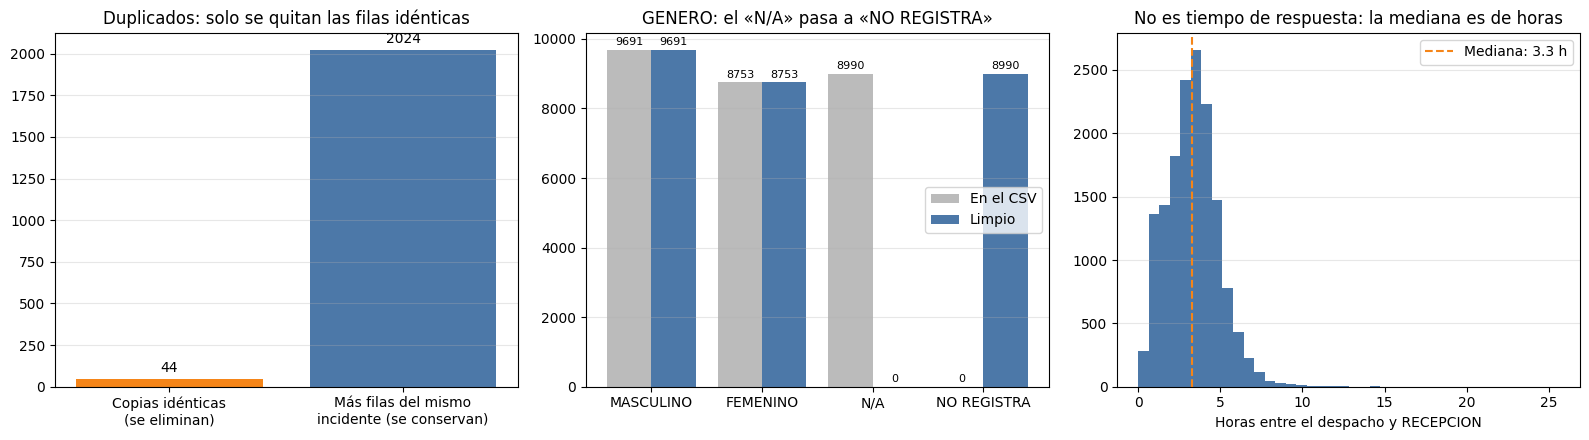

In [ ]:
crudo = spark.read.option("header", "true").option("sep", ";").schema(esquema).csv(archivos_csv)
total = crudo.count()
sin_copias = crudo.dropDuplicates()
copias_identicas = total - sin_copias.count()
mismo_incidente = sin_copias.count() - sin_copias.select("NUMERO_INCIDENTE").distinct().count()
genero_csv = {r['GENERO']: r['count'] for r in crudo.groupBy("GENERO").count().collect()}
limpio = spark.read.option("header", "true").option("sep", ";").option("nullValue", "N/A").schema(esquema).csv(archivos_csv)
genero_limpio = {r['GENERO'] or 'NO REGISTRA': r['count'] for r in limpio.groupBy("GENERO").count().collect()}
minutos = limpio.select(((to_timestamp("RECEPCION", "yyyy-MM-dd HH:mm:ss").cast("long") -
                             to_timestamp("FECHA_INICIO_DESPLAZAMIENTO_MOVIL", "yyyy-MM-dd HH:mm:ss").cast("long")) / 60)
                           .alias("m")).dropna().toPandas()["m"]

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
b = ejes[0].bar(['Copias idénticas\n(se eliminan)', 'Más filas del mismo\nincidente (se conservan)'],
                [copias_identicas, mismo_incidente], color=['#F58518', '#4C78A8'])
ejes[0].bar_label(b, padding=3)
ejes[0].set_title('Duplicados: solo se quitan las filas idénticas')

categorias = ['MASCULINO', 'FEMENINO', 'N/A', 'NO REGISTRA']
x = np.arange(len(categorias))
b1 = ejes[1].bar(x - 0.2, [genero_csv.get(k, 0) for k in categorias], 0.4, label='En el CSV', color='#bbbbbb')
b2 = ejes[1].bar(x + 0.2, [genero_limpio.get(k, 0) for k in categorias], 0.4, label='Limpio', color='#4C78A8')
ejes[1].bar_label(b1, padding=2, fontsize=8)
ejes[1].bar_label(b2, padding=2, fontsize=8)
ejes[1].set_xticks(x, categorias)
ejes[1].set_title('GENERO: el «N/A» pasa a «NO REGISTRA»')
ejes[1].legend()

ejes[2].hist(minutos / 60, bins=40, color='#4C78A8')
ejes[2].axvline(minutos.median() / 60, color='#F58518', linestyle='--', label=f'Mediana: {minutos.median() / 60:.1f} h')
ejes[2].set_xlabel('Horas entre el despacho y RECEPCION')
ejes[2].set_title('No es tiempo de respuesta: la mediana es de horas')
ejes[2].legend()
for e in ejes:
    e.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(SALIDA + "1_calidad_datos.png", dpi=300, bbox_inches='tight')
plt.show()

## 6. Tres ejecuciones: PySpark frente a Pandas

Las métricas que pide la guía: tiempo total, memoria pico, throughput y tasa de éxito de validaciones. El tiempo va
de la lectura a la exportación del Parquet.

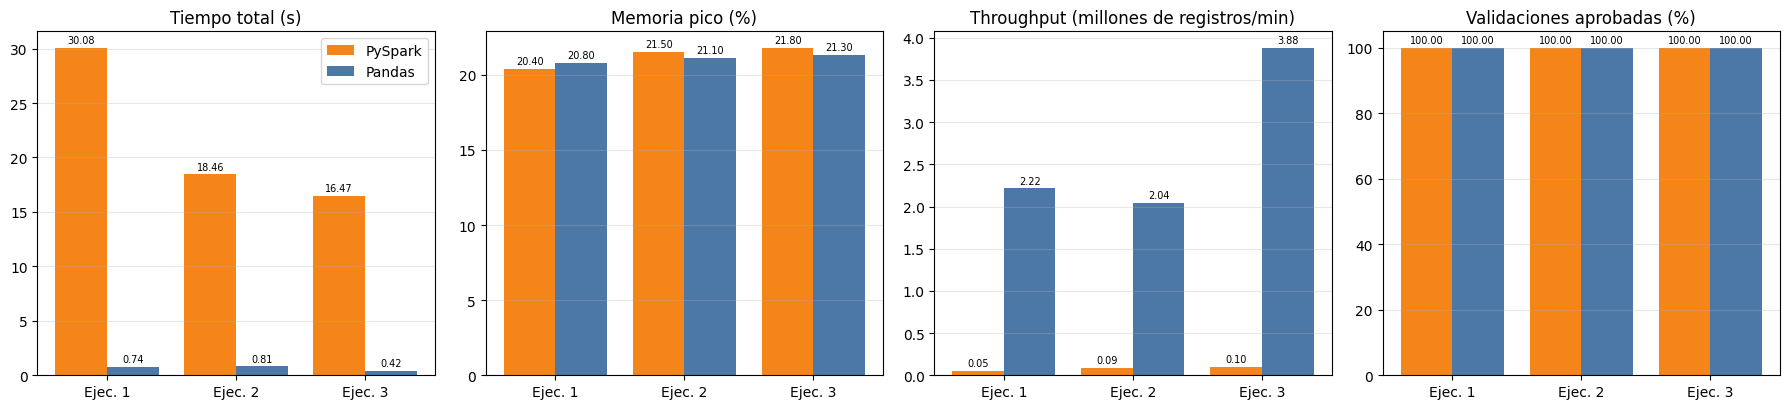

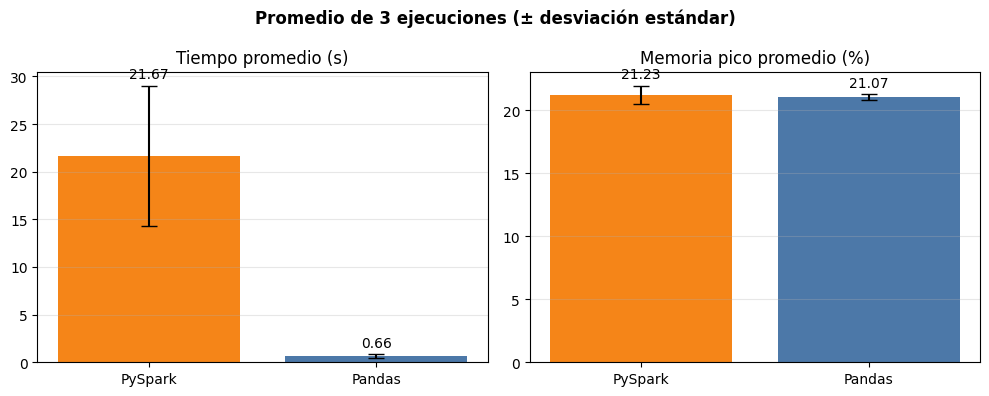

In [ ]:
filas = []
for n in (1, 2, 3):
    for herramienta, funcion in (('PySpark', pipeline_spark), ('Pandas', pipeline_pandas)):
        gc.collect()
        with MonitorMemoria() as m:
            segundos, c = funcion(archivos_csv, f"{TEMPORAL}/{herramienta}_{n}")
        ok = controles(c)
        escribir_log(f"{SALIDA}logs/log_{herramienta.lower()}_ejecucion_{n}.txt", herramienta, n, segundos, c, ok, m.pico)
        filas.append({'herramienta': herramienta, 'ejecucion': n, 'tiempo_s': segundos, 'memoria_pico_pct': m.pico,
                      'throughput_reg_min': c['total_raw'] / (segundos / 60),
                      'validaciones_pct': sum(ok) / len(ok) * 100})
metricas = pd.DataFrame(filas)
metricas.to_csv(SALIDA + "metricas_3_ejecuciones.csv", index=False)
metricas['throughput_millones'] = metricas['throughput_reg_min'] / 1e6

colores = {'PySpark': '#F58518', 'Pandas': '#4C78A8'}
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for e, columna, titulo in zip(ejes, ['tiempo_s', 'memoria_pico_pct', 'throughput_millones', 'validaciones_pct'],
                              ['Tiempo total (s)', 'Memoria pico (%)', 'Throughput (millones de registros/min)',
                               'Validaciones aprobadas (%)']):
    for i, h in enumerate(('PySpark', 'Pandas')):
        d = metricas[metricas['herramienta'] == h]
        b = e.bar(d['ejecucion'] + (i - 0.5) * 0.4, d[columna], 0.4, color=colores[h], label=h)
        e.bar_label(b, labels=[f'{v:,.2f}' for v in d[columna]], padding=2, fontsize=7)
    e.set_xticks([1, 2, 3], ['Ejec. 1', 'Ejec. 2', 'Ejec. 3'])
    e.set_title(titulo)
    e.grid(True, axis='y', alpha=0.3)
ejes[0].legend()
plt.tight_layout()
plt.savefig(SALIDA + "2_metricas_3_ejecuciones.png", dpi=300, bbox_inches='tight')
plt.show()

prom = metricas.groupby('herramienta')[['tiempo_s', 'memoria_pico_pct']].agg(['mean', 'std'])
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for e, columna, titulo in zip(ejes, ['tiempo_s', 'memoria_pico_pct'], ['Tiempo promedio (s)', 'Memoria pico promedio (%)']):
    g = prom[columna].loc[['PySpark', 'Pandas']]
    b = e.bar(g.index, g['mean'], yerr=g['std'], capsize=6, color=[colores[h] for h in g.index])
    e.bar_label(b, labels=[f'{v:.2f}' for v in g['mean']], padding=3)
    e.set_title(titulo)
    e.grid(True, axis='y', alpha=0.3)
plt.suptitle('Promedio de 3 ejecuciones (± desviación estándar)', fontweight='bold')
plt.tight_layout()
plt.savefig(SALIDA + "3_comparacion_pandas.png", dpi=300, bbox_inches='tight')
plt.show()

### 6.1 Parquet final en Google Drive

Se guarda en Drive el Parquet de la última ejecución de PySpark, como evidencia del PoC.

In [ ]:
PARQUET_DRIVE = SALIDA + "parquet_poc"
shutil.rmtree(PARQUET_DRIVE, ignore_errors=True)
shutil.copytree(f"{TEMPORAL}/PySpark_3", PARQUET_DRIVE)
filas_drive = spark.read.parquet(PARQUET_DRIVE).count()
carpetas = [r for r, _, archivos in os.walk(PARQUET_DRIVE) if any(a.endswith('.parquet') for a in archivos)]
print(f"✓ Parquet guardado en {PARQUET_DRIVE}: {filas_drive:,} filas en {len(carpetas)} carpetas año/mes/localidad")

✓ Parquet guardado en /content/drive/MyDrive/BigData_U2/resultados/poc_sencillo/parquet_poc: 27,390 filas en 64 carpetas año/mes/localidad


## 7. Escalabilidad: 1 y 2 años

Se repiten los 3 meses 4 veces (1 año) y 8 veces (2 años). Son datos **sintéticos**: a cada copia se le cambia el
número de incidente.

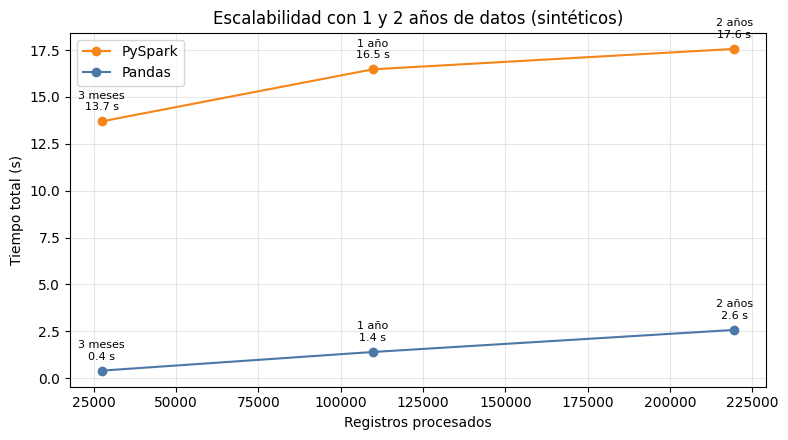

In [ ]:
def replicar(veces):
    carpeta = f"/content/escala_x{veces}"
    os.makedirs(carpeta, exist_ok=True)
    rutas = []
    for r in archivos_csv:
        base = pd.read_csv(r, sep=';', dtype=str, encoding='utf-8-sig', keep_default_na=False)
        copia = pd.concat([base.assign(NUMERO_INCIDENTE=base['NUMERO_INCIDENTE'] + (f'-c{k}' if k else ''))
                           for k in range(veces)])
        destino = f"{carpeta}/{os.path.basename(r)}"
        copia.to_csv(destino, sep=';', index=False, encoding='utf-8-sig')
        rutas.append(destino)
    return rutas


escala = []
for veces, etiqueta in ((1, '3 meses'), (4, '1 año'), (8, '2 años')):
    rutas = archivos_csv if veces == 1 else replicar(veces)
    for herramienta, funcion in (('PySpark', pipeline_spark), ('Pandas', pipeline_pandas)):
        gc.collect()
        segundos, c = funcion(rutas, f"{TEMPORAL}/escala_{herramienta}_{veces}")
        escala.append({'periodo': etiqueta, 'registros': c['total_raw'], 'herramienta': herramienta, 'tiempo_s': segundos})
escala = pd.DataFrame(escala)
escala.to_csv(SALIDA + "escalabilidad.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for h, color in colores.items():
    d = escala[escala['herramienta'] == h]
    ax.plot(d['registros'], d['tiempo_s'], 'o-', color=color, label=h)
    for _, f in d.iterrows():
        ax.annotate(f"{f['periodo']}\n{f['tiempo_s']:.1f} s", (f['registros'], f['tiempo_s']),
                    textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
ax.set_xlabel('Registros procesados')
ax.set_ylabel('Tiempo total (s)')
ax.set_title('Escalabilidad con 1 y 2 años de datos (sintéticos)')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(SALIDA + "4_escalabilidad.png", dpi=300, bbox_inches='tight')
plt.show()

## 8. Resultado

Con estos volúmenes, Pandas es más rápido porque PySpark paga un costo fijo de arranque y coordinación. Esa ventaja
se reduce a medida que crecen los datos, y PySpark es la opción que permite repartir el trabajo entre varias máquinas
cuando ya no quepan en una. En `resultados/poc_sencillo` quedan el Parquet (`parquet_poc`), los 4 gráficos, los CSV
de métricas para el Excel y un log por ejecución.

In [ ]:
spark.stop()
print('✓ Listo:', sorted(os.listdir(SALIDA)))

✓ Listo: ['1_calidad_datos.png', '2_metricas_3_ejecuciones.png', '3_comparacion_pandas.png', '4_escalabilidad.png', 'escalabilidad.csv', 'logs', 'metricas_3_ejecuciones.csv', 'parquet_poc']
